# EKF comparison · constant and variable CO₂ solubility

Each figure compares **one chemical model** under the two existing gas formulations. S and G/F are shown separately; only the two EKF trajectories appear in each panel.

- Same chemical parameters, CO₂ observations, causal 30-minute windows and filter noise settings; offline chemistry is used for evaluation only.
- Constant formulation: $C_{sat}=1.5$ g/L, $k_La=0.074679$ h⁻¹, gain $=0.635239$.
- Variable formulation: $C_{sat}=3.295\exp[(7\times10^{-5}a-0.02905)T-0.0179a-0.00111S]p_{CO_2}$, where $a=E/7.8924$ (% vol), $T$ is °C, $S$ is g/L and $p_{CO_2}=1$ bar. Recalibrated $(k_La, gain)$: S $(0.137966,0.658678)$; G/F $(0.150080,0.646064)$.

This compares the **complete current formulations**, including the revised gas transfer/desorption law and recalibrated gas parameters. It does not isolate the solubility correlation alone. Gas calibration: LAB019–021; gas holdout: LAB016–018. Chemical calibration used separate fermentations; the analytical comparisons here are holdout evaluations.

RMSE has the plotted variable’s units. YAN includes nutrition samples. Initial values remain visible as Samples and are excluded from post-initial chemical RMSE; substituted zero G+F values retain the existing censoring policy. No chemical sample is assimilated.

The solubility correlation is reproduced from [Liger-Belair et al. (2023), Eq. 1](https://doi.org/10.1021/acsomega.3c01812). Its use for fermenting must and the assumed CO₂ partial pressure remain modeling assumptions.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display
from IPython.utils.capture import capture_output
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
INPUTS = {
    'Constant solubility': ROOT/'notebooks/EKF/03_zenteno_single_sugar_co2_only.source.ipynb',
    'Variable solubility': ROOT/'notebooks/EKF/06_zenteno_single_sugar_variable_solubility.source.ipynb',
}
INPUT_HASHES = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS.values()}
def run_filters(label):
    notebook = nbformat.read(INPUTS[label], as_version=4)
    namespace = {'__name__': '__main__'}
    # Recompute the original data preparation and both EKFs, without running
    # their mixed-model plotting/evaluation cell or modifying any input file.
    with capture_output() as log:
        for index in (1, 3, 5):
            exec(compile(notebook.cells[index].source, str(INPUTS[label])+f':cell{index}', 'exec'), namespace)
    print(label + ': six fermentations completed for both models.')
    return namespace
RUNS = {}


In [2]:
RUNS['Constant solubility'] = run_filters('Constant solubility')

Constant solubility: six fermentations completed for both models.


In [3]:
RUNS['Variable solubility'] = run_filters('Variable solubility')

Variable solubility: six fermentations completed for both models.


In [4]:
LABS = RUNS['Variable solubility']['LABS']
TRAIN = RUNS['Variable solubility']['TRAIN']
REFERENCE = RUNS['Variable solubility']
v = REFERENCE['v']
chemical_observations = REFERENCE['chemical_observations']
CHEMICAL_COLUMNS = REFERENCE['CHEMICAL_COLUMNS']
COLORS = {'Constant solubility': '#D55E00', 'Variable solubility': '#0072B2'}
STYLES = {'Constant solubility': '--', 'Variable solubility': '-'}
RESULTS = {model: {label: ns['RESULTS' if model == 'S' else 'RESULTS_GF']
                   for label, ns in RUNS.items()} for model in ('S', 'G/F')}
for model, cases in RESULTS.items():
    for lab in LABS:
        a, b = [res[lab]['sensor'] for res in cases.values()]
        for col in ('t_h', 'measured', 'valid', 'assimilate'):
            np.testing.assert_allclose(a[col], b[col], equal_nan=True)
        for state in ('X', 'N', 'GF', 'E', 'Cd'):
            np.testing.assert_allclose(cases['Constant solubility'][lab]['frame']['EKF_'+state].iloc[0],
                                       cases['Variable solubility'][lab]['frame']['EKF_'+state].iloc[0])
METRICS = []
FIGURES = {}
def observation_arrays(lab, state):
    if lab in TRAIN:
        o = chemical_observations(v.chem, lab, state)
        tt = o.t_h.to_numpy(); yy = o[CHEMICAL_COLUMNS[state]].to_numpy()
    elif state == 'X':
        o = v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h', 'X_viable_g_l'])
        tt = o.t_h.to_numpy(); yy = o.X_viable_g_l.to_numpy()
    else:
        o = pd.DataFrame(); tt = np.array([]); yy = np.array([])
    mask = np.isfinite(tt) & np.isfinite(yy) & (tt > 0) & (tt <= v.horizons[lab])
    if state == 'GF' and 'GF_zero_substitution' in o:
        mask &= ~o.GF_zero_substitution.astype(str).str.lower().eq('true').to_numpy()
    return o, tt, yy, mask

def compare(model, state, title):
    factor = 1000 if state == 'N' else 1
    unit = 'g/(L h)' if state == 'CO2' else ('mg/L' if state == 'N' else 'g/L')
    fig, axs = plt.subplots(2, 3, figsize=(15, 7.4))
    for ax, lab in zip(axs.flat, LABS):
        errors = {}
        if state == 'CO2':
            sensor = RESULTS[model]['Variable solubility'][lab]['sensor']
            ax.plot(sensor.t_h, sensor.measured, c='black', lw=.7, label='Samples')
        elif state != 'Cd':
            o, tt, yy, mask = observation_arrays(lab, state)
            sample_label = 'G+F' if state == 'GF' else 'Samples'
            ax.scatter(tt[mask], yy[mask]*factor, c='black', s=20, label=sample_label, zorder=5)
            first = RESULTS[model]['Variable solubility'][lab]['frame']
            ax.scatter([0], [first['EKF_'+state].iloc[0]*factor], c='black', s=20, label=sample_label, zorder=5)
            if state == 'GF':
                density = v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
                density = density.loc[density.t_h.between(0, v.horizons[lab])]
                ax.scatter(density.t_h, 2.5*(density.density_g_l-1000), marker='D', facecolors='none',
                           edgecolors='#009E73', s=22, label='G+F from density', zorder=4)
        for label, results in RESULTS[model].items():
            result = results[lab]
            if state == 'CO2':
                q = result['sensor']; tx = q.t_h; prediction = q.forecast
                valid = q.valid & np.isfinite(q.measured)
                error = q.loc[valid, 'forecast'] - q.loc[valid, 'measured']
            else:
                f = result['frame']; tx = f.t_h; prediction = f['EKF_'+state]*factor
                error = (np.interp(tt[mask], f.t_h, f['EKF_'+state])-yy[mask])*factor if state != 'Cd' else []
            ax.plot(tx, prediction, color=COLORS[label], ls=STYLES[label], lw=1.5, label=label)
            if len(error):
                rmse = float(np.sqrt(np.mean(np.asarray(error)**2))); errors[label] = rmse
                METRICS.append(dict(model=model, solubility=label, LAB=lab, variable=state,
                                    n=len(error), RMSE=rmse, unit=unit,
                                    gas_split='Calibration' if lab in TRAIN else 'Holdout'))
        for t, dose in REFERENCE['batches'][lab].pulses['N']:
            ax.axvline(t, c='gray', ls=':', lw=.8, label='N pulse')
        handles, labels = ax.get_legend_handles_labels()
        unique = dict(zip(labels, handles))
        legend_title = '\n'.join(f'RMSE {label} = {value:.3f} {unit}' for label, value in errors.items())
        ax.legend(unique.values(), unique.keys(), loc='best', fontsize=6.8, title=legend_title or None,
                  title_fontsize=6.8, framealpha=.9)
        ax.set(title=lab, xlabel='Time [h]', ylabel=title+' ['+unit+']')
        ax.grid(alpha=.2)
    context = 'forecast before correction' if state == 'CO2' else ('model state' if state == 'Cd' else 'chemical holdout')
    fig.suptitle(f'{title} · EKF {model} · {context}', y=.995)
    fig.tight_layout(pad=.65, h_pad=1.0, w_pad=.8, rect=(0, 0, 1, .975))
    FIGURES[(model, state)] = fig
    plt.show()


## CO₂

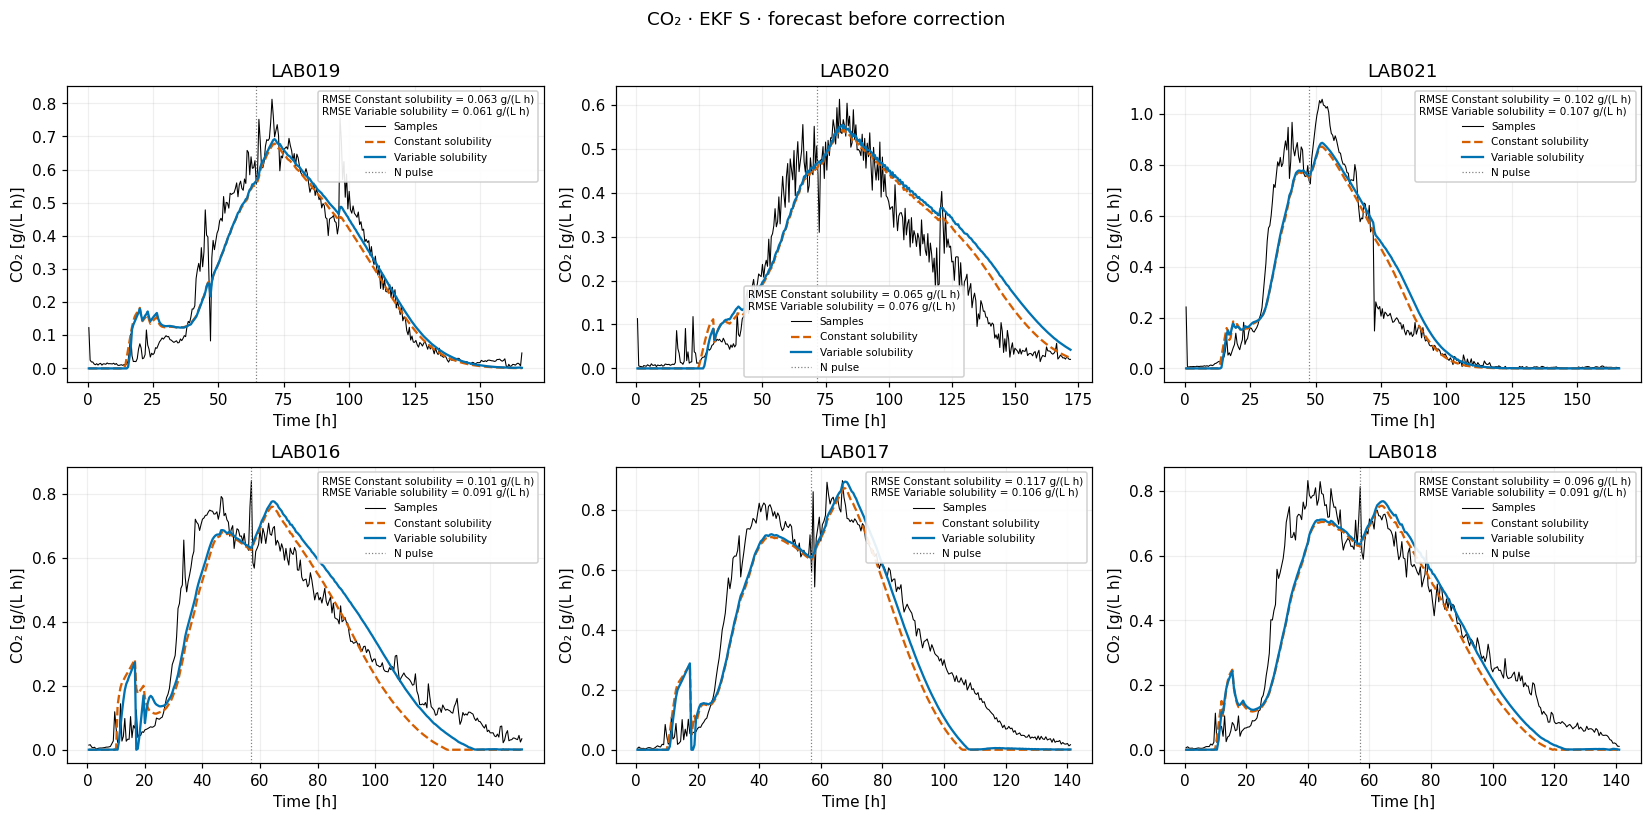

In [5]:
compare('S', 'CO2', 'CO₂')

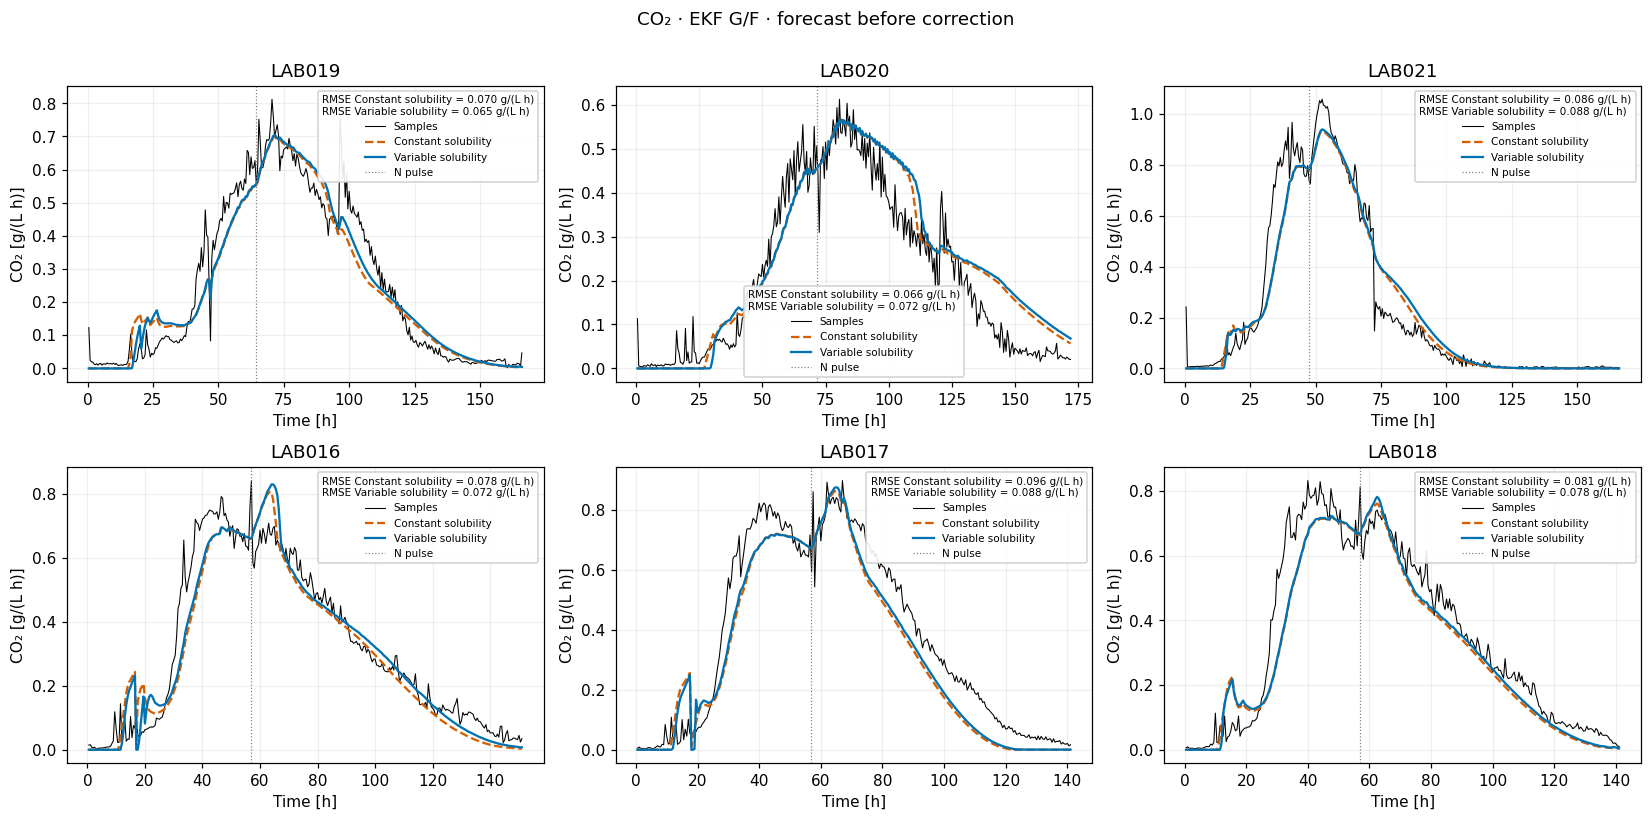

In [6]:
compare('G/F', 'CO2', 'CO₂')

## Biomass

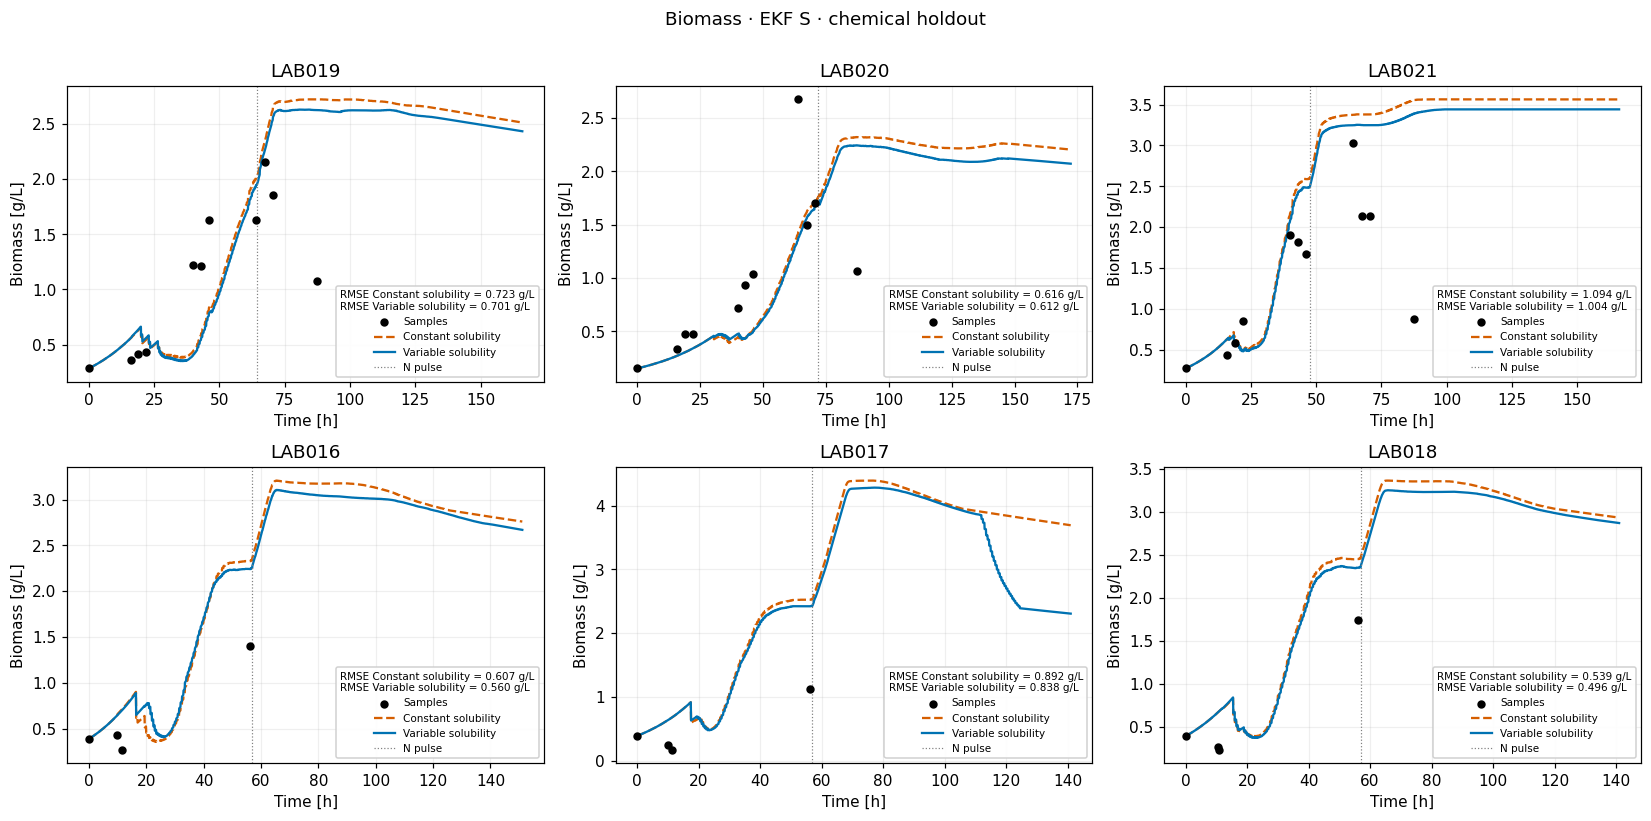

In [7]:
compare('S', 'X', 'Biomass')

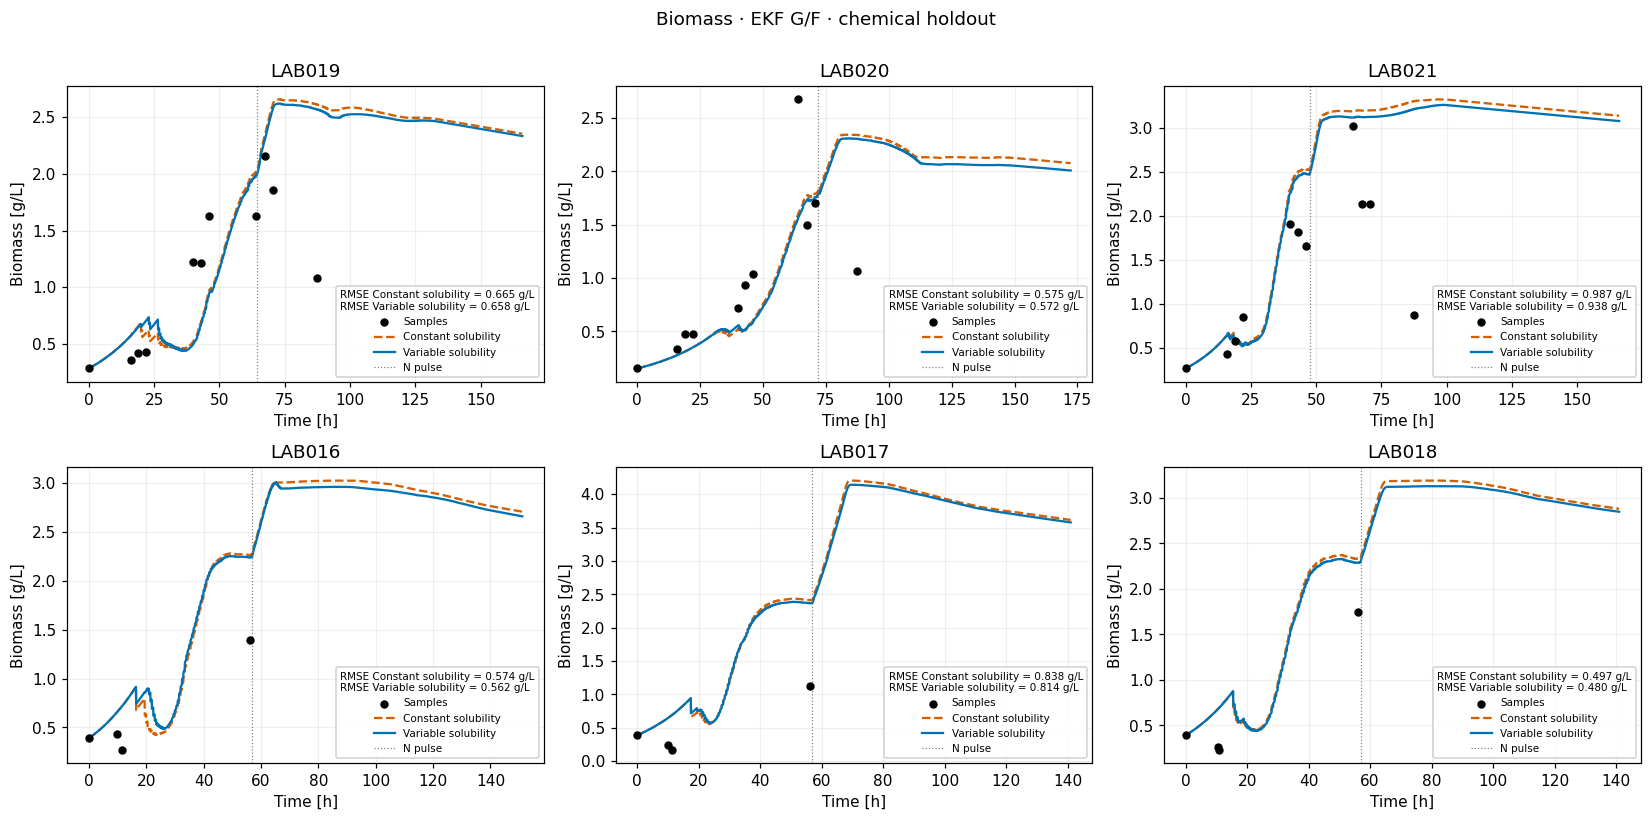

In [8]:
compare('G/F', 'X', 'Biomass')

## YAN

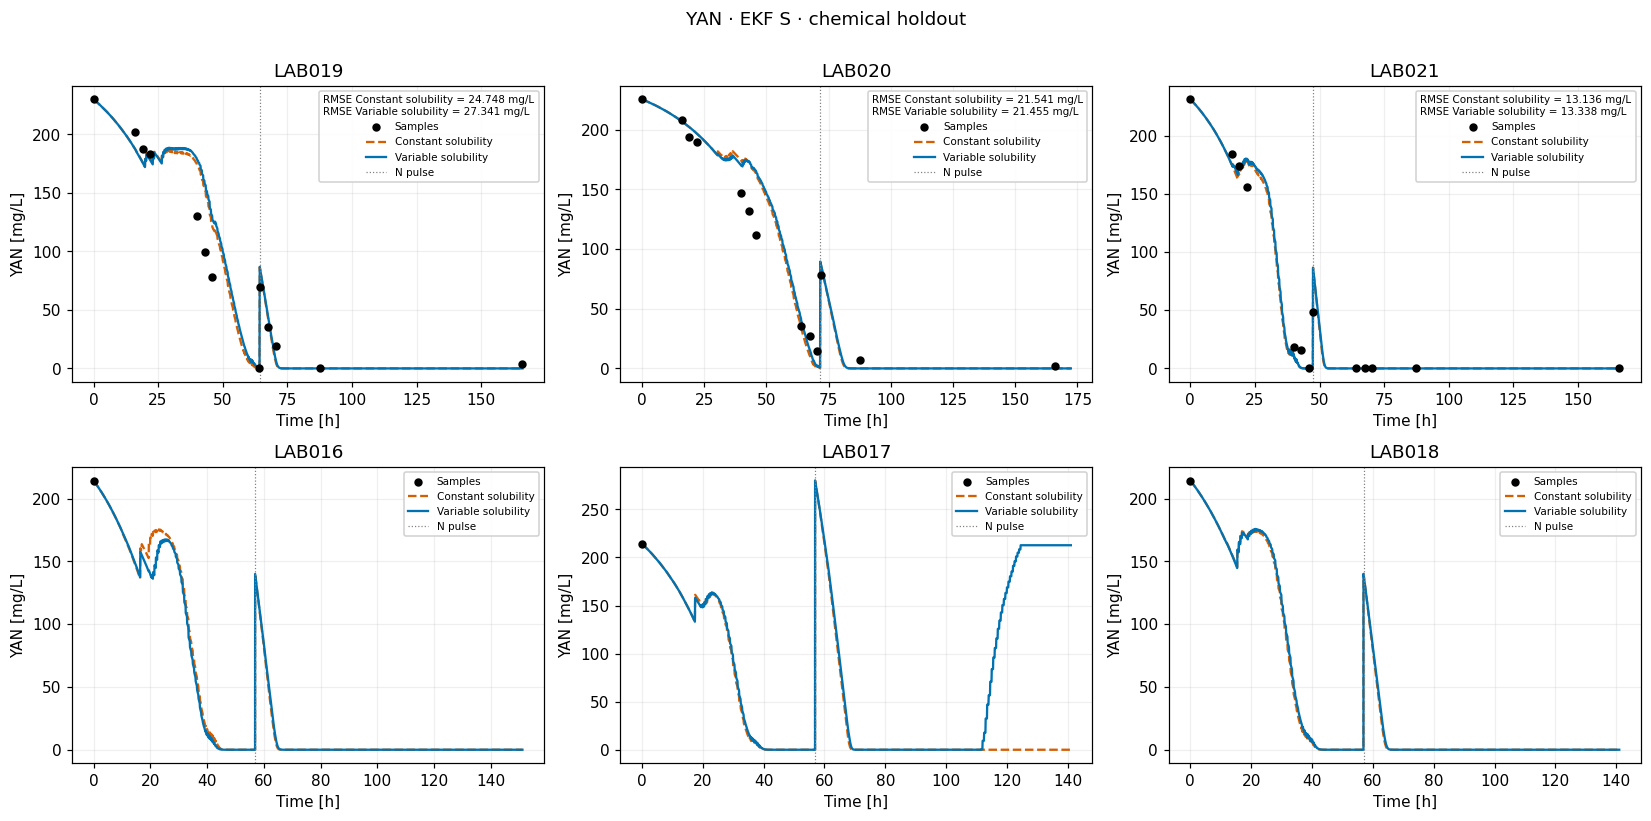

In [9]:
compare('S', 'N', 'YAN')

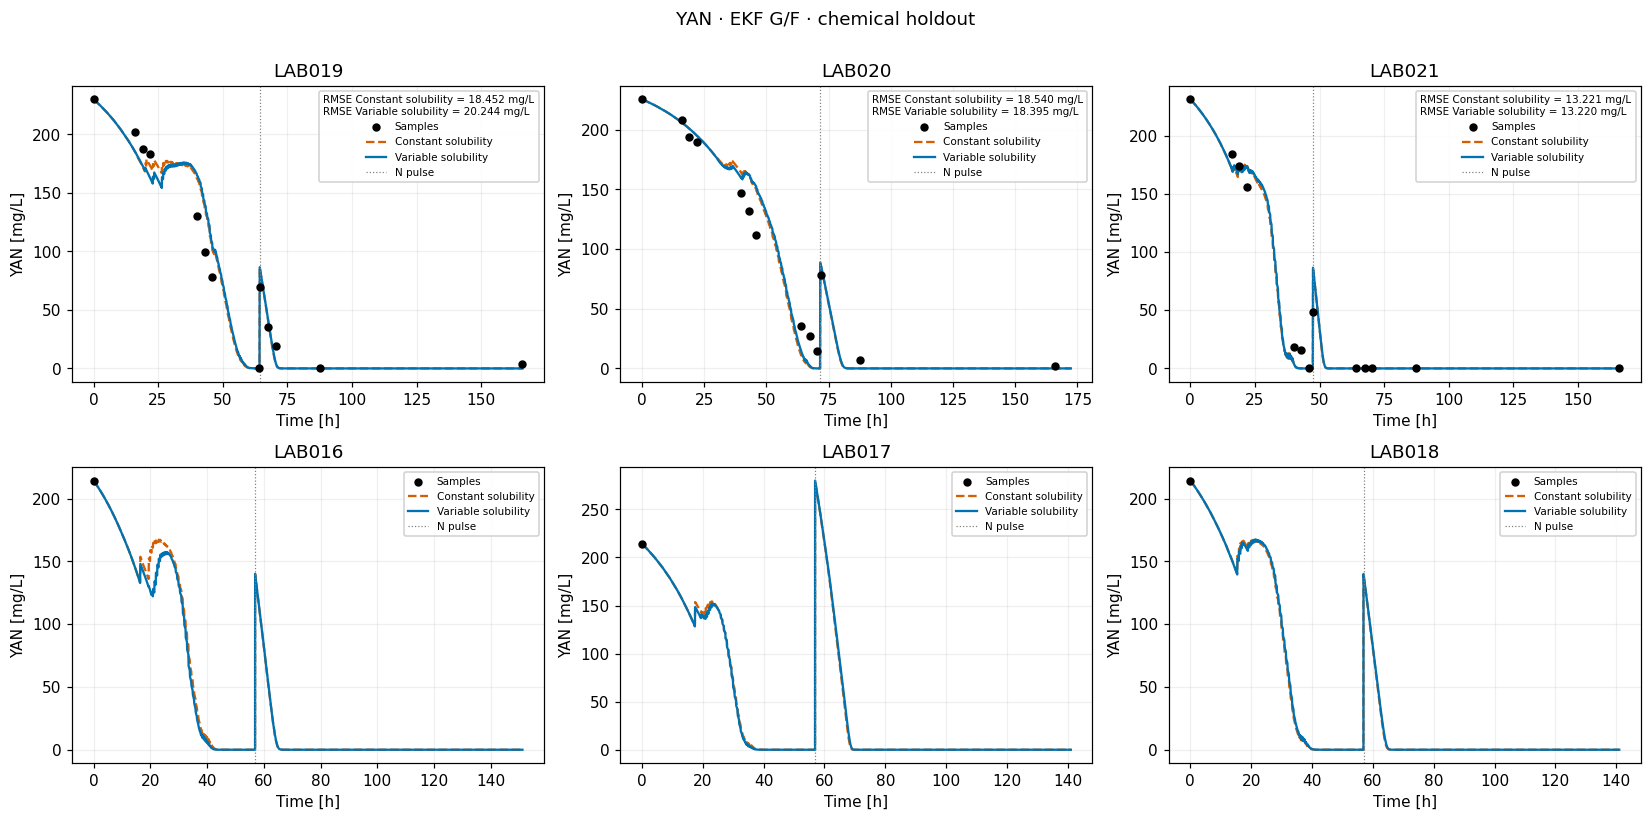

In [10]:
compare('G/F', 'N', 'YAN')

## Glucose + fructose

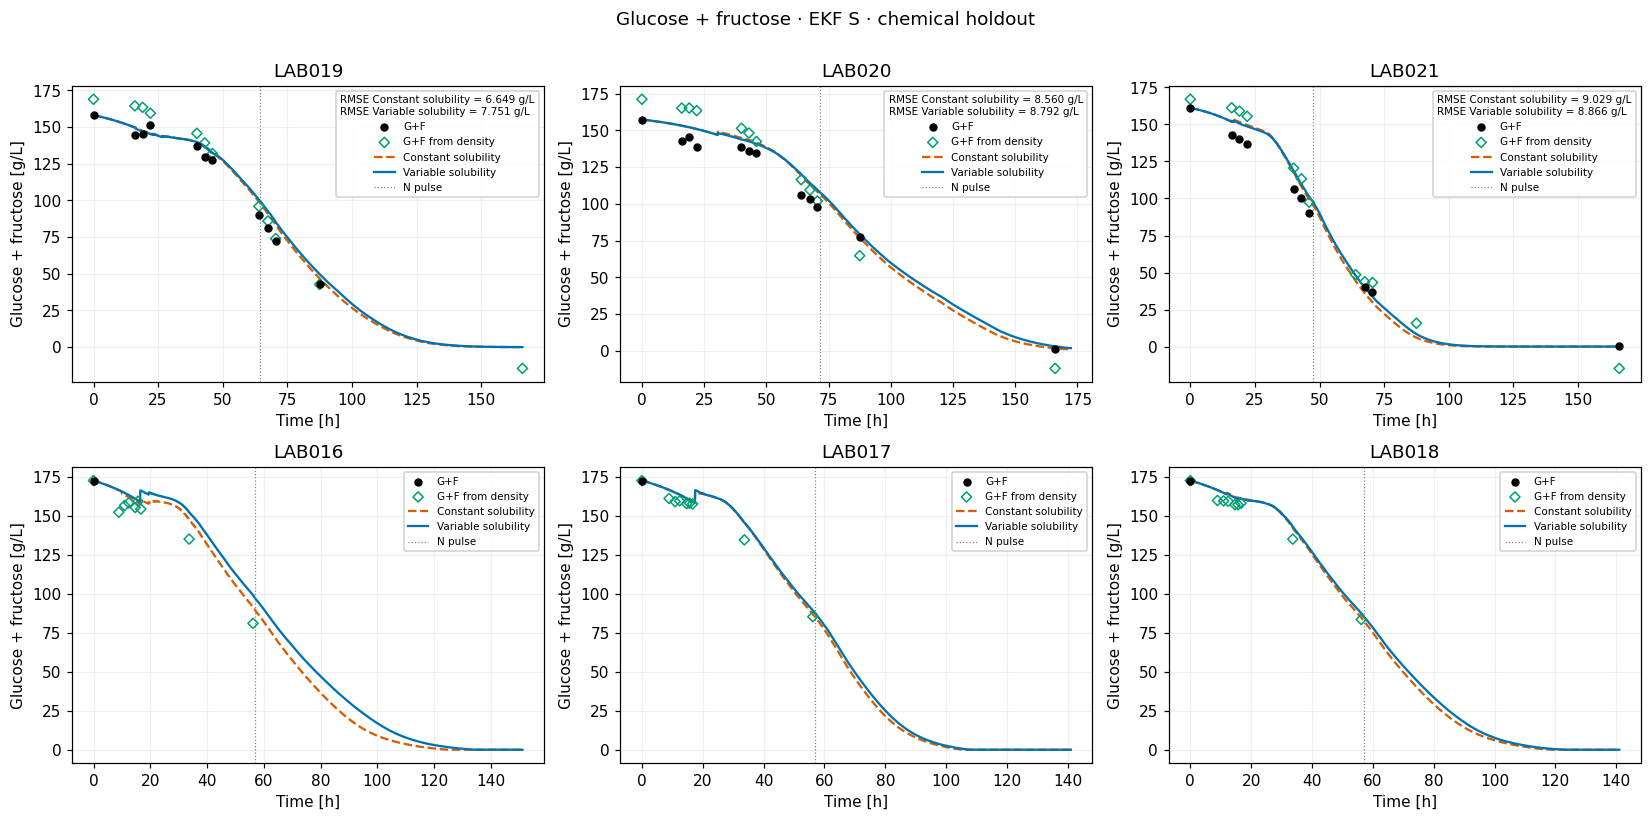

In [11]:
compare('S', 'GF', 'Glucose + fructose')

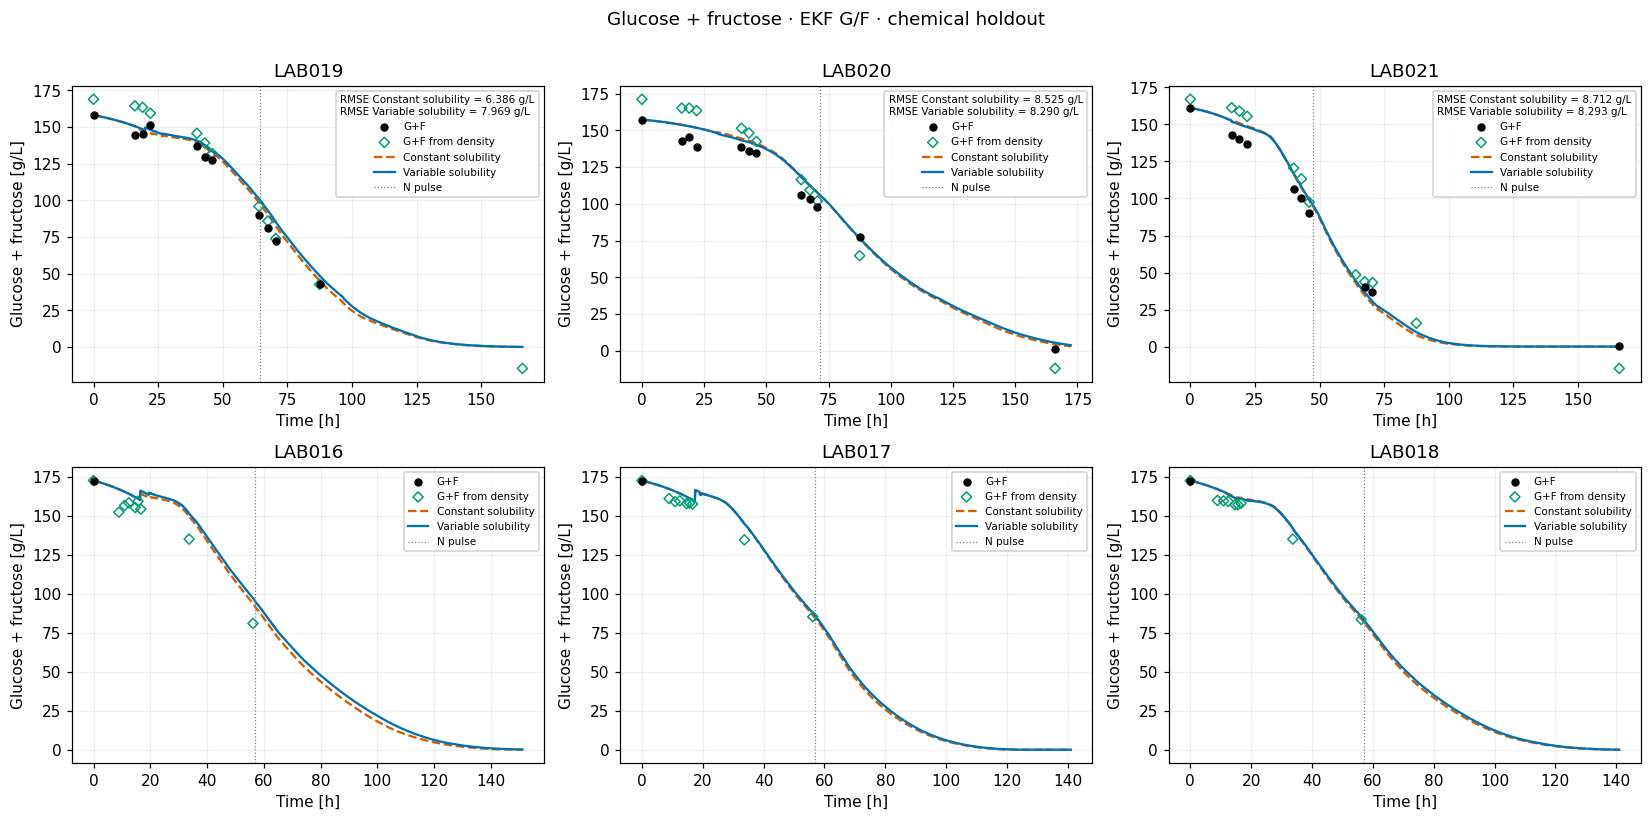

In [12]:
compare('G/F', 'GF', 'Glucose + fructose')

## Ethanol

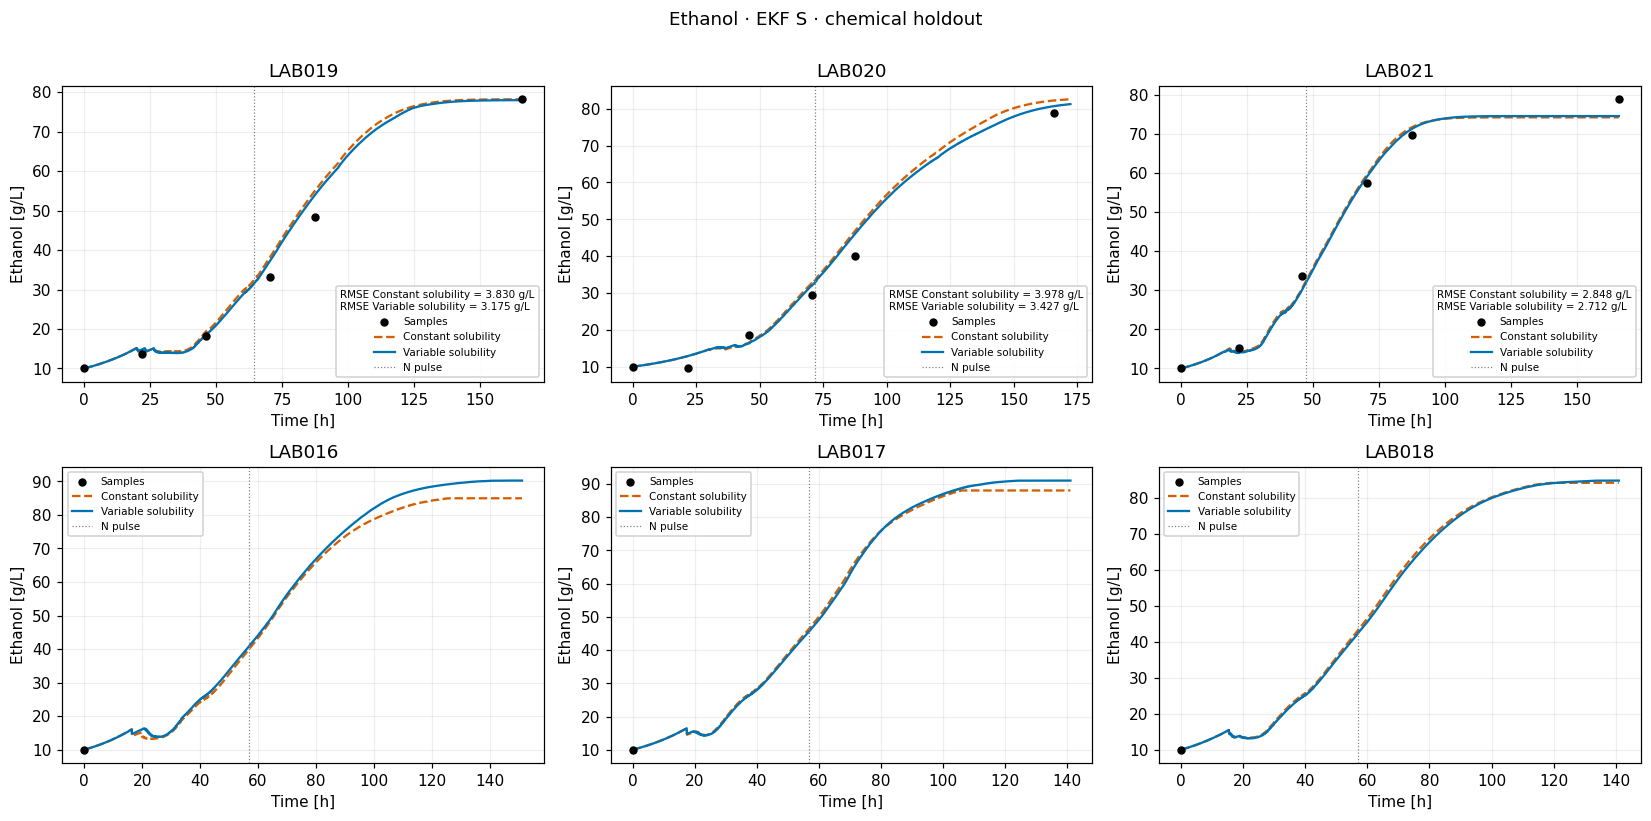

In [13]:
compare('S', 'E', 'Ethanol')

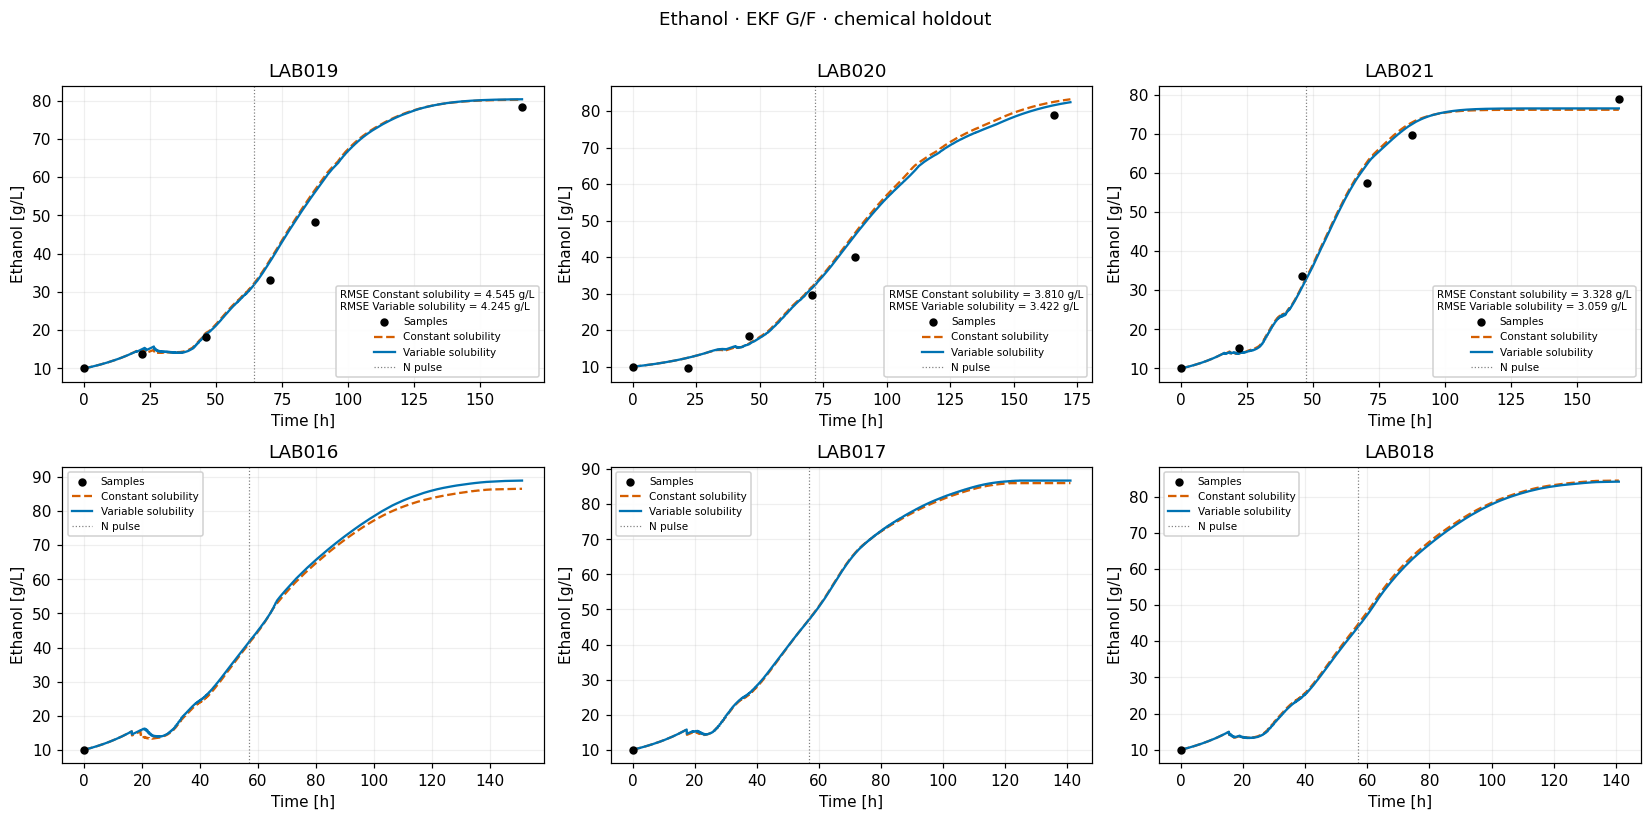

In [14]:
compare('G/F', 'E', 'Ethanol')

## Dissolved CO₂

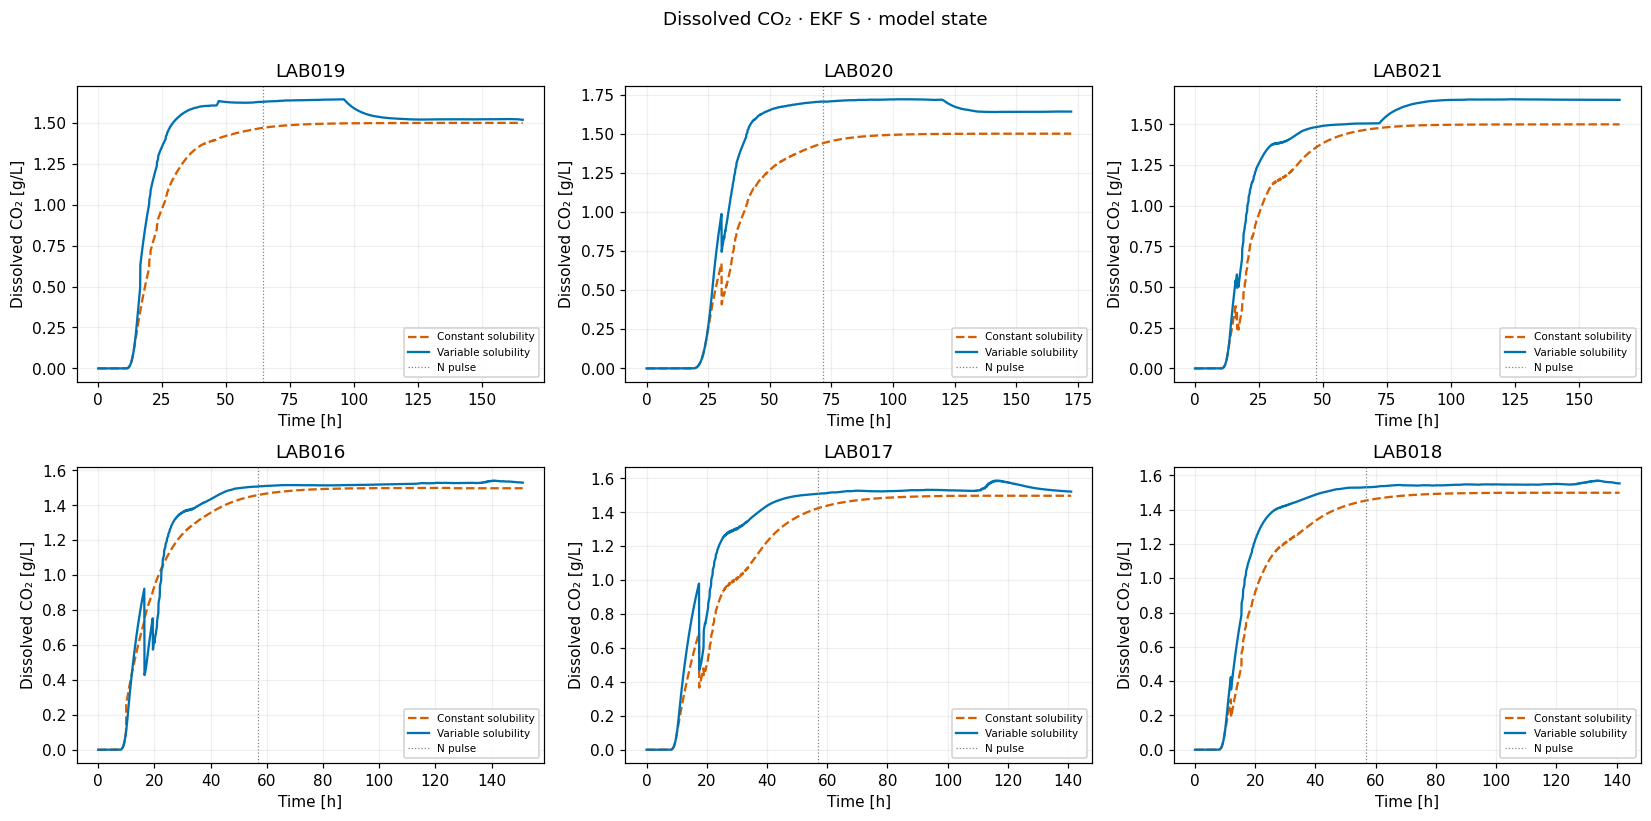

In [15]:
compare('S', 'Cd', 'Dissolved CO₂')

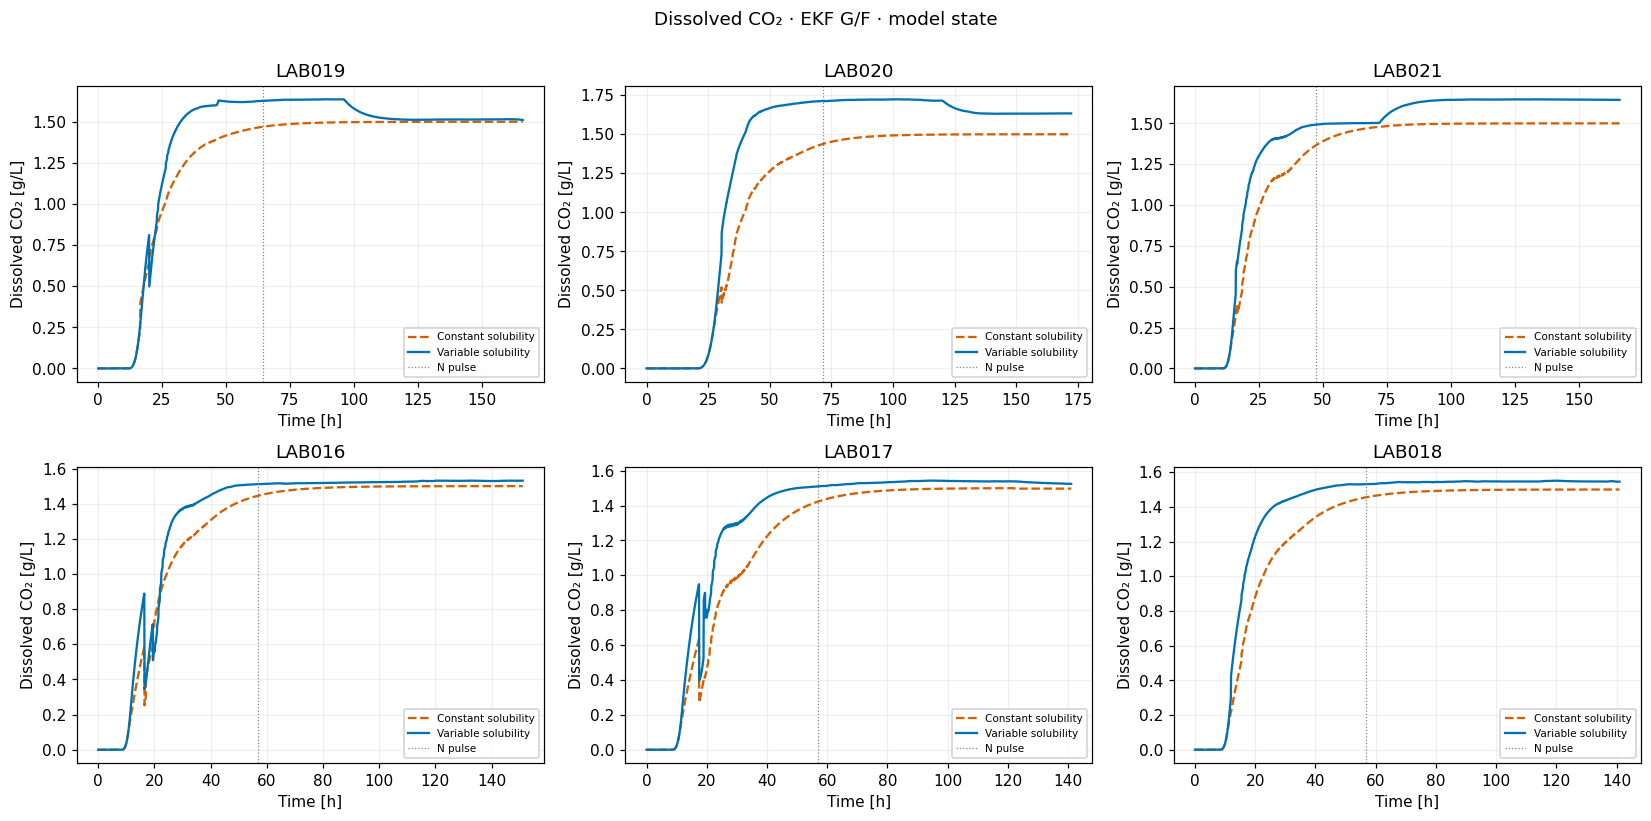

In [16]:
compare('G/F', 'Cd', 'Dissolved CO₂')

## Individual sugars · G/F model

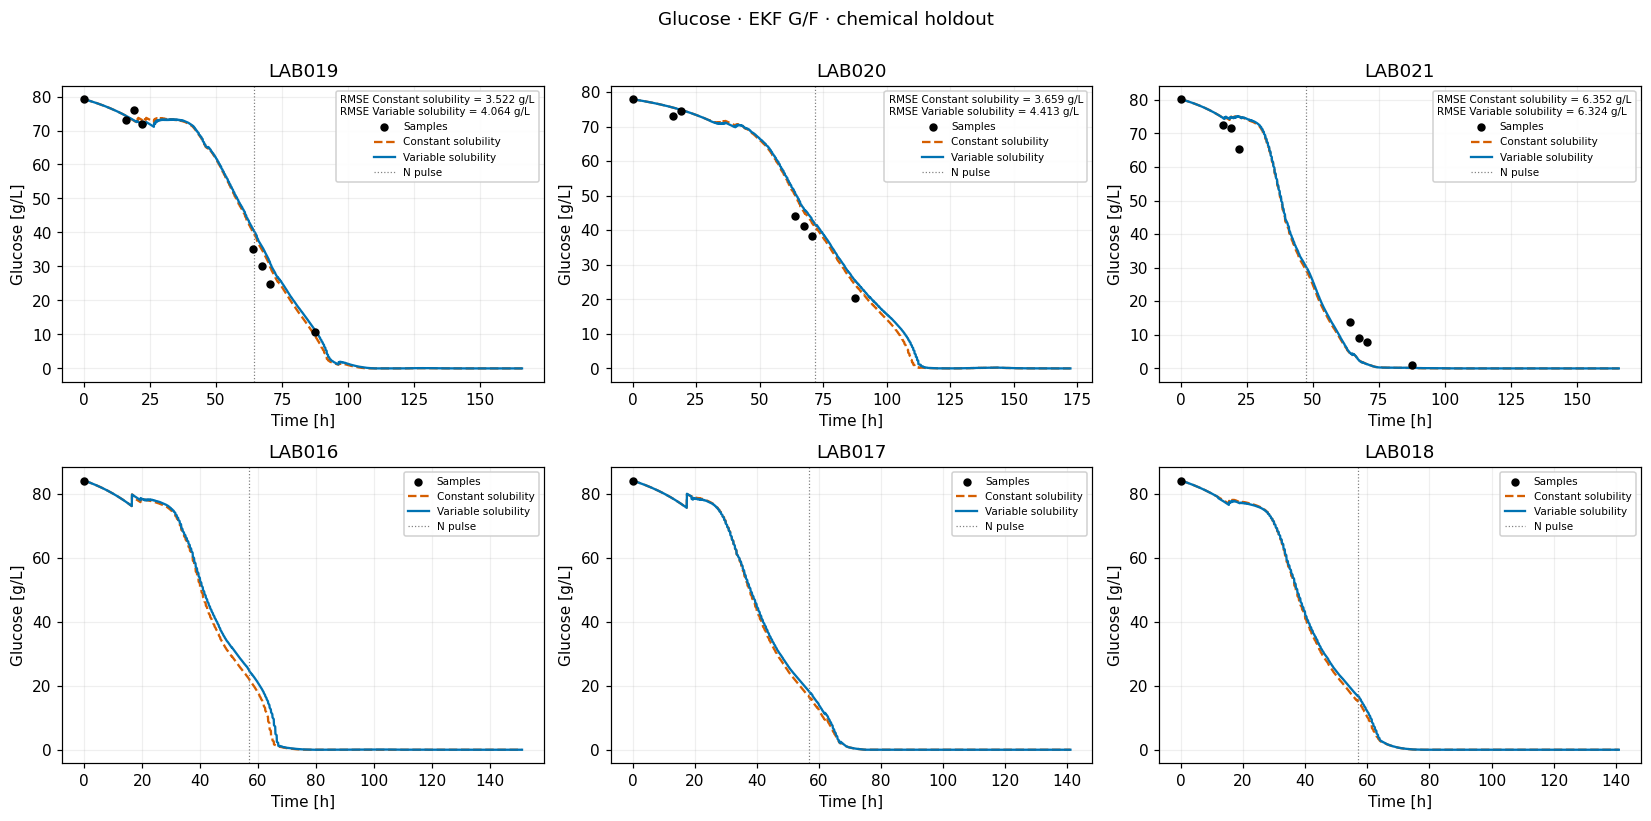

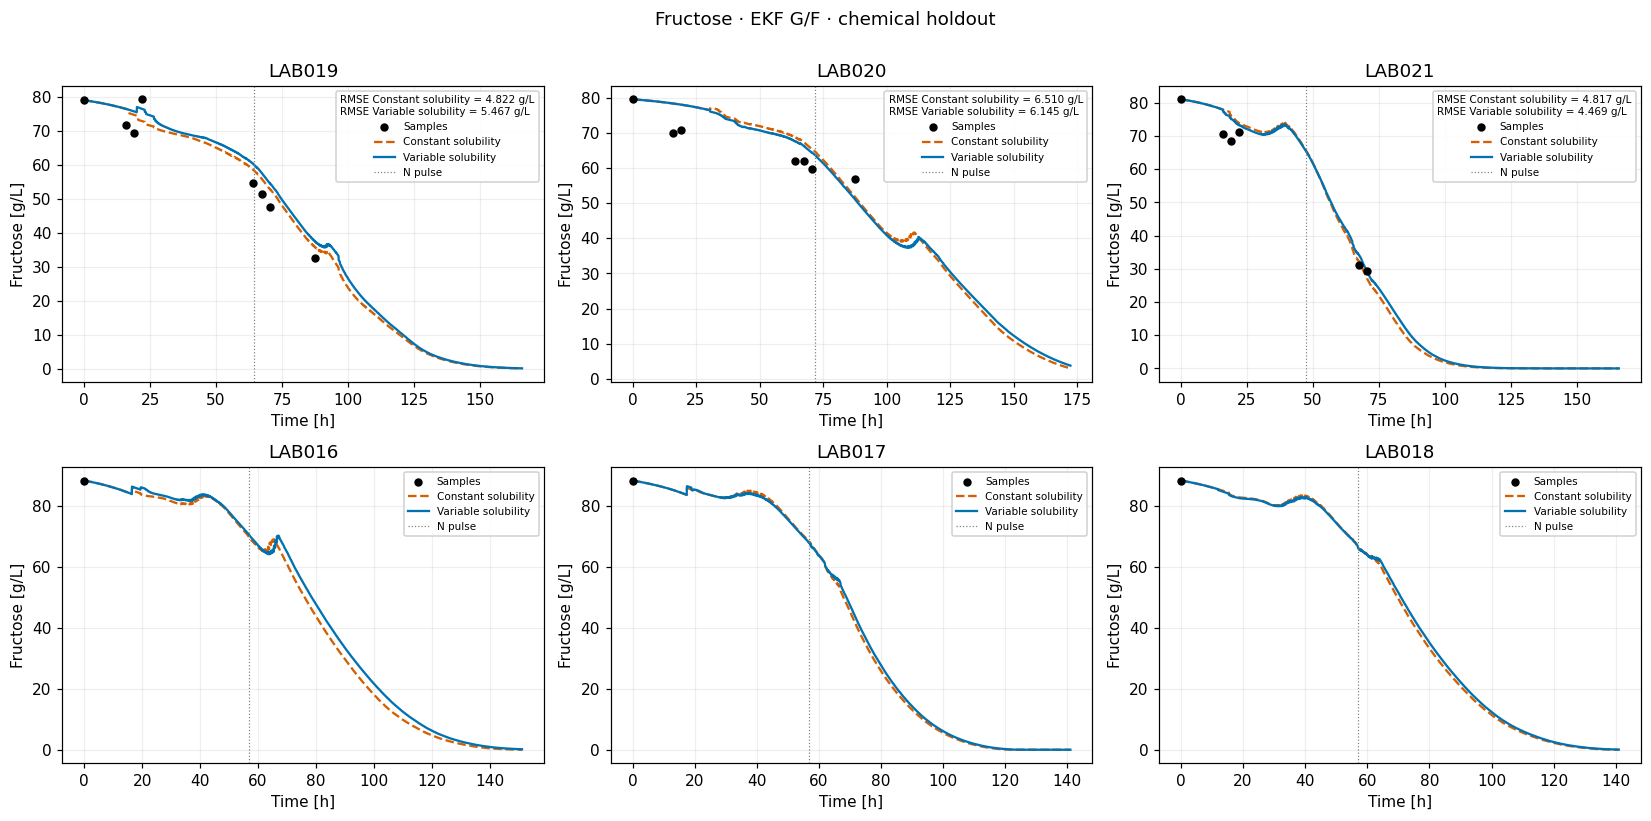

In [17]:
compare('G/F', 'G', 'Glucose')
compare('G/F', 'F', 'Fructose')

## RMSE comparison

CO₂ rows distinguish gas calibration and holdout. Chemical rows compare independent analytical samples. The summary is the arithmetic mean of per-fermentation RMSE, not a pooled RMSE. Negative change means a lower RMSE for variable solubility. No RMSE is reported for dissolved CO₂ without measurements.

In [18]:
metrics = pd.DataFrame(METRICS)
yan = metrics.loc[metrics.variable.eq('N')]
assert yan.n.eq(12).all() and len(yan) == 12
comparison = metrics.pivot(index=['model','variable','unit','gas_split','LAB','n'], columns='solubility', values='RMSE')
comparison['Change [%]'] = 100*(comparison['Variable solubility']/comparison['Constant solubility']-1)
display(comparison.round(4))
summary_data = metrics.copy()
summary_data['evaluation'] = np.where(summary_data.variable.eq('CO2'), 'Gas '+summary_data.gas_split.str.lower(), 'Chemical holdout')
summary = summary_data.groupby(['model','variable','unit','evaluation','solubility']).RMSE.mean().unstack('solubility')
summary['Change [%]'] = 100*(summary['Variable solubility']/summary['Constant solubility']-1)
display(summary.round(4))
assert all(hashlib.sha256((ROOT/path).read_bytes()).hexdigest() == digest for path, digest in INPUT_HASHES.items())
print('Identical observation windows, masks and initial conditions verified. All 12 post-initial YAN samples per LAB included, including nutrition samples.')
print('Input notebook SHA-256:', json.dumps(INPUT_HASHES, indent=2))


Identical observation windows, masks and initial conditions verified. All 12 post-initial YAN samples per LAB included, including nutrition samples.
Input notebook SHA-256: {
  "notebooks\\EKF\\03_zenteno_single_sugar_co2_only.source.ipynb": "a3a31e93984e2553223de4a9b613e5e9030fc82490b8a881f5b1dea9e092b096",
  "notebooks\\EKF\\06_zenteno_single_sugar_variable_solubility.source.ipynb": "55415a81277bb85e520a02dcccab8a4926c37841c4880dab94b5a3e190562e21"
}


solubility                                     Constant solubility  ...  Change [%]
model variable unit    gas_split   LAB    n                         ...            
G/F   CO2      g/(L h) Calibration LAB019 332               0.0700  ...     -7.7999
                                   LAB020 344               0.0665  ...      8.3291
                                   LAB021 332               0.0857  ...      2.3227
                       Holdout     LAB016 302               0.0778  ...     -7.4723
                                   LAB017 282               0.0960  ...     -8.7599
                                   LAB018 282               0.0810  ...     -3.7913
      E        g/L     Calibration LAB019 5                 4.5446  ...     -6.5891
                                   LAB020 5                 3.8104  ...    -10.2036
                                   LAB021 5                 3.3276  ...     -8.0644
      F        g/L     Calibration LAB019 7                 4.8223  ...     13.3766
                                   LAB020 6                 6.5095  ...     -5.5930
                                   LAB021 5                 4.8174  ...     -7.2312
      G        g/L     Calibration LAB019 7                 3.5225  ...     15.3716
                                   LAB020 6                 3.6590  ...     20.5965
                                   LAB021 7                 6.3523  ...     -0.4482
      GF       g/L     Calibration LAB019 10                6.3859  ...     24.7883
                                   LAB020 11                8.5248  ...     -2.7599
                                   LAB021 9                 8.7117  ...     -4.8015
      N        mg/L    Calibration LAB019 12               18.4519  ...      9.7123
                                   LAB020 12               18.5396  ...     -0.7783
                                   LAB021 12               13.2210  ...     -0.0053
      X        g/L     Calibration LAB019 10                0.6654  ...     -1.1050
                                   LAB020 10                0.5746  ...     -0.3954
                                   LAB021 10                0.9872  ...     -4.9527
                       Holdout     LAB016 3                 0.5738  ...     -2.0969
                                   LAB017 3                 0.8375  ...     -2.7976
                                   LAB018 3                 0.4966  ...     -3.4328
S     CO2      g/(L h) Calibration LAB019 332               0.0631  ...     -3.7338
                                   LAB020 344               0.0650  ...     16.9802
                                   LAB021 332               0.1020  ...      4.8876
                       Holdout     LAB016 302               0.1010  ...     -9.8294
                                   LAB017 282               0.1171  ...     -9.4031
                                   LAB018 282               0.0964  ...     -5.6394
      E        g/L     Calibration LAB019 5                 3.8304  ...    -17.0987
                                   LAB020 5                 3.9780  ...    -13.8526
                                   LAB021 5                 2.8479  ...     -4.7856
      GF       g/L     Calibration LAB019 10                6.6494  ...     16.5612
                                   LAB020 11                8.5598  ...      2.7129
                                   LAB021 9                 9.0289  ...     -1.8060
      N        mg/L    Calibration LAB019 12               24.7484  ...     10.4772
                                   LAB020 12               21.5411  ...     -0.4015
                                   LAB021 12               13.1364  ...      1.5345
      X        g/L     Calibration LAB019 10                0.7232  ...     -3.0744
                                   LAB020 10                0.6158  ...     -0.5988
                                   LAB021 10                1.0938  ...     -8.1976
                       Holdout     LAB016 3         

solubility                               Constant solubility  ...  Change [%]
model variable unit    evaluation                             ...            
G/F   CO2      g/(L h) Gas calibration                0.0741  ...      0.9291
                       Gas holdout                    0.0849  ...     -6.7868
      E        g/L     Chemical holdout               3.8942  ...     -8.1882
      F        g/L     Chemical holdout               5.3831  ...     -0.4171
      G        g/L     Chemical holdout               4.5113  ...      9.3589
      GF       g/L     Chemical holdout               7.8742  ...      3.9343
      N        mg/L    Chemical holdout              16.7375  ...      3.2803
      X        g/L     Chemical holdout               0.6892  ...     -2.6850
S     CO2      g/(L h) Gas calibration                0.0767  ...      5.9401
                       Gas holdout                    0.1048  ...     -8.3861
      E        g/L     Chemical holdout               3.5521  ...    -12.5963
      GF       g/L     Chemical holdout               8.0793  ...      4.8287
      N        mg/L    Chemical holdout              19.8086  ...      4.5570
      X        g/L     Chemical holdout               0.7450  ...     -5.7942

[14 rows x 3 columns]

## Interpretation limits

The comparison retains the current filter settings and does not retune their noise matrices. LAB016–018 lack post-initial analytical YAN measurements, so their YAN trajectories have no empirical RMSE. The late YAN rise in the variable-solubility S EKF for LAB017 is a measurement-correction artifact under these settings and cannot be validated from YAN samples. Dissolved CO₂ trajectories are inferred states, not measured validation data.